<a href="https://colab.research.google.com/github/Mikhailo88/MN-Praktychni-K4/blob/main/%D0%9B%D0%A0_7_%D0%9E%D0%BB%D1%8C%D1%85%D0%BE%D0%B2%D0%B5%D0%BD%D0%BA%D0%BE_%D0%A4%D0%86%D0%A24_8.ipynb" target="_parent"><img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Open In Colab"/></a>

# Лабораторна робота № 7
## Логістична регресія. «Врятувати принцесу»


**Мета:** виконати бінарну класифікацію для датасету *Cure the Princess*, побудувати логістичну регресію, підібрати її параметри та порівняти з SVM і деревом рішень.

**Датасет:** [завантажити файл](https://drive.google.com/file/d/1ctefpJ5A0ZiwewxqLaC3RBeydLKLTgvH/view?usp=drive_link).

**Завдання:** допишіть код у клітинках із позначкою `TODO`, запустіть усі потрібні клітинки, після кожного етапу коротко прокоментуйте результати. Готові числові результати у шаблоні навмисно не наведено.

https://www.kaggle.com/datasets/unmoved/cure-the-princess

### 1. Імпорт бібліотек

In [4]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns

from sklearn.model_selection import train_test_split, GridSearchCV, RandomizedSearchCV
from sklearn.preprocessing import StandardScaler
from sklearn.linear_model import LogisticRegression
from sklearn.svm import SVC
from sklearn.tree import DecisionTreeClassifier
from sklearn.metrics import accuracy_score, confusion_matrix, classification_report, f1_score

import os

### 2. Завантаження даних

Використайте **один** із двох способів. Якщо обираєте завантаження з комп'ютера, виконайте перший блок. Якщо KaggleHub — другий. Файл має назву `data.csv`.

In [5]:
# Варіант 2. Завантаження датасету через KaggleHub
import kagglehub

# Download latest version
path = kagglehub.dataset_download("unmoved/cure-the-princess")

print("Path to dataset files:", path)

Using Colab cache for faster access to the 'cure-the-princess' dataset.
Path to dataset files: /kaggle/input/cure-the-princess


In [8]:
df = pd.read_csv(os.path.join(path, 'data.csv'))
df

,Phoenix Feather,Unicorn Horn,Dragon's Blood,Mermaid Tears,Fairy Dust,Goblin Toes,Witch's Brew,Griffin Claw,Troll Hair,Kraken Ink,Minotaur Horn,Basilisk Scale,Chimera Fang,Cured
0,2.4,18.7,18.4,27.9,7.9,9.6,18.3,13.2,2.5,26.0,10.5,26.2,12.5,0
1,2.1,6.0,15.0,13.3,15.6,13.1,11.0,5.0,7.2,26.0,1.5,13.3,6.2,0
2,17.2,13.9,23.8,6.8,10.7,15.8,19.4,2.7,15.4,21.2,11.1,16.6,11.4,1
3,8.4,9.7,6.8,26.9,4.6,29.1,14.6,19.7,18.0,20.8,13.6,13.9,8.1,1
4,22.1,10.8,16.4,10.5,22.0,23.4,2.6,18.2,23.8,11.3,5.5,16.8,16.2,0
...,...,...,...,...,...,...,...,...,...,...,...,...,...,...
2333,9.4,2.2,15.8,5.9,29.7,18.7,11.5,13.1,15.3,22.5,10.1,4.7,13.8,0
2334,12.1,7.6,20.6,5.3,18.9,19.1,9.4,11.9,21.8,12.0,26.7,8.4,24.4,1
2335,15.2,33.2,7.2,14.5,16.0,16.7,1.2,32.5,34.5,25.9,3.9,18.0,19.2,1
2336,2.0,17.0,33.2,13.2,29.1,35.5,19.7,30.3,30.7,4.3,15.7,20.5,2.1,1


### Опис даних

Цільова змінна **`Cured`**: `1` — принцесу вилікувано; `0` — не вилікувано. Інші стовпці — характеристики магічних інгредієнтів.

1. **Phoenix Feather** (Перо фенікса) — перо міфічної птиці фенікса, який згорає, а потім відроджується з власного попелу. Це символізує відродження, вічне життя та силу.

2. **Unicorn Horn** (Ріг єдинорога) — ріг міфічної істоти єдинорога, який часто асоціюється з чистотою та цілющою силою. У багатьох легендах вважалося, що ріг єдинорога має магічні властивості, зокрема здатність лікувати отруєння.

3. **Dragon's Blood** (Кров дракона) — кров дракона, міфічної істоти, часто вважається дуже потужним магічним зіллям або елементом. Це може символізувати силу, енергію чи небезпеку.

4. **Mermaid Tears**(Сльози русалки) — сльози міфічної істоти — русалки. У різних культурах їх вважають рідкісним і дуже цінним елементом, що має магічні властивості, часто пов'язані з любов'ю або трагічними подіями.

5. **Fairy Dust** (Пилок феї) — магічний пилок, що належить феям у народних казках. Зазвичай він використовується для чарівних перетворень, польотів або інших магічних дій.

6. **Goblin Toes** (Палець гобліна) — палець гобліна, вигаданої істоти з міфів, що зазвичай асоціюється з хитрістю і злісними чарами. Цей елемент може мати магічну силу або використовуватися в темних чарах.

7. **Witch's Brew** (Зілля відьми) — зілля, яке варить відьма, часто містить магічні або отруйні інгредієнти. Це часто асоціюється з темною магією або чарами.

8. **Griffin Claw** (Лапа грифона) — лапа грифона, міфічної істоти, що є поєднанням орла і лева. Грифон символізує силу та відвагу, а його лапа може вважатися потужним магічним предметом.

9. **Troll Hair** (Волосся троля) — волосся троля, ще однієї міфічної істоти, часто описуваної як агресивна та неприємна істота. Волосся троля може бути використане в магічних або темних ритуалах.

10. **Kraken Ink** (Чорнила кракена) — чорнила, що отримуються від кракена, гігантської морської істоти. У фентезі вони можуть використовуватись для темних магічних ритуалів або для створення важливих символів.

11. **Minotaur Horn** (Ріг минотавра) — ріг минотавра, міфічного чудовиська з головою бика і тілом людини. Ріг минотавра може символізувати силу і агресію, і в магічному контексті бути потужним інгредієнтом.

12. **Basilisk Scale** (Луска базиліска) — луска базиліска, міфічної істоти, яка може вбивати своїм поглядом. Луска базиліска у фентезі часто використовується як компонент у потужних зіллях або зброї.

13. **Chimera Fang** (Зуб хімери) — зуб хімери, міфічної істоти, яка поєднує різні тварини, такі як лев, коза і змія. Зуб хімери часто використовується в магічних зіллях або як символ сили та багатофункціональності.

14. **Cured** (Вилікувана) — цільова змінна: 1 — принцесу вилікувано, 0 — не вилікувано.

### 3. Первинний огляд датасету

Дослідіть структуру та розміри даних, пропущені значення, дублікати й описову статистику. Дайте короткий висновок про якість даних.

In [10]:
df.head()

,Phoenix Feather,Unicorn Horn,Dragon's Blood,Mermaid Tears,Fairy Dust,Goblin Toes,Witch's Brew,Griffin Claw,Troll Hair,Kraken Ink,Minotaur Horn,Basilisk Scale,Chimera Fang,Cured
0,2.4,18.7,18.4,27.9,7.9,9.6,18.3,13.2,2.5,26.0,10.5,26.2,12.5,0
1,2.1,6.0,15.0,13.3,15.6,13.1,11.0,5.0,7.2,26.0,1.5,13.3,6.2,0
2,17.2,13.9,23.8,6.8,10.7,15.8,19.4,2.7,15.4,21.2,11.1,16.6,11.4,1
3,8.4,9.7,6.8,26.9,4.6,29.1,14.6,19.7,18.0,20.8,13.6,13.9,8.1,1
4,22.1,10.8,16.4,10.5,22.0,23.4,2.6,18.2,23.8,11.3,5.5,16.8,16.2,0


In [11]:
df.info()

<class 'pandas.core.frame.DataFrame'>
RangeIndex: 2338 entries, 0 to 2337
Data columns (total 14 columns):
 #   Column           Non-Null Count  Dtype  
---  ------           --------------  -----  
 0   Phoenix Feather  2338 non-null   float64
 1   Unicorn Horn     2338 non-null   float64
 2   Dragon's Blood   2338 non-null   float64
 3   Mermaid Tears    2338 non-null   float64
 4   Fairy Dust       2338 non-null   float64
 5   Goblin Toes      2338 non-null   float64
 6   Witch's Brew     2338 non-null   float64
 7   Griffin Claw     2338 non-null   float64
 8   Troll Hair       2338 non-null   float64
 9   Kraken Ink       2338 non-null   float64
 10  Minotaur Horn    2338 non-null   float64
 11  Basilisk Scale   2338 non-null   float64
 12  Chimera Fang     2338 non-null   float64
 13  Cured            2338 non-null   int64  
dtypes: float64(13), int64(1)
memory usage: 255.8 KB


In [12]:
df.shape

(2338, 14)

In [16]:
# TODO: перевірте кількість пропусків і дублікатів
df.isnull().sum()

,0
Phoenix Feather,0
Unicorn Horn,0
Dragon's Blood,0
Mermaid Tears,0
Fairy Dust,0
Goblin Toes,0
Witch's Brew,0
Griffin Claw,0
Troll Hair,0
Kraken Ink,0


In [14]:
df.duplicated().sum()

np.int64(0)

In [15]:
# TODO: виведіть описову статистику
df.describe()

,Phoenix Feather,Unicorn Horn,Dragon's Blood,Mermaid Tears,Fairy Dust,Goblin Toes,Witch's Brew,Griffin Claw,Troll Hair,Kraken Ink,Minotaur Horn,Basilisk Scale,Chimera Fang,Cured
count,2338.000000,2338.000000,2338.000000,2338.000000,2338.000000,2338.000000,2338.000000,2338.000000,2338.000000,2338.000000,2338.000000,2338.000000,2338.000000,2338.000000
mean,15.365697,10.946749,16.115654,13.627973,15.069504,14.157271,12.328914,14.911206,16.871685,14.890590,10.916125,15.371600,12.084003,0.496578
std,8.669969,7.225162,8.372518,7.545244,8.349340,7.831476,7.709753,8.132678,9.579027,8.014197,7.045195,8.559139,8.047540,0.500095
min,1.000000,1.000000,1.000000,1.000000,1.000000,1.000000,1.000000,1.000000,1.000000,1.000000,1.000000,1.000000,1.000000,0.000000
25%,8.500000,5.300000,9.600000,7.600000,8.625000,7.900000,6.325000,8.400000,8.900000,8.800000,5.200000,8.800000,5.600000,0.000000
50%,14.700000,9.500000,15.800000,13.100000,14.500000,13.500000,11.200000,14.400000,16.300000,14.400000,9.700000,14.800000,10.500000,0.000000
75%,21.300000,15.575000,22.000000,19.000000,20.700000,19.500000,16.900000,20.500000,24.000000,20.400000,15.375000,21.100000,17.275000,1.000000
max,42.100000,34.100000,40.800000,35.800000,40.400000,37.800000,37.300000,39.400000,44.800000,39.500000,33.700000,42.000000,37.800000,1.000000


### 4. Поділ даних на навчальну й тестову вибірки

Відокремте `Cured` від ознак. Поділіть дані у співвідношенні **80% / 20%** із `random_state=42`.

**Важливо:** дослідження кореляцій і викидів, а також обчислення параметрів стандартизації виконуйте **тільки на навчальній вибірці**.

In [17]:
# Відокремлення ознак та цільової змінної
X = df.drop(columns=["Cured"])
y = df["Cured"]

# Поділ на навчальну та тестову вибірки
X_train, X_test, y_train, y_test = train_test_split(
    X, y,
    test_size=0.2,
    random_state=42
)

print("Розмір навчальної вибірки:", X_train.shape)
print("Розмір тестової вибірки:", X_test.shape)

print("Розмір y_train:", y_train.shape)
print("Розмір y_test:", y_test.shape)

Розмір навчальної вибірки: (1870, 13)
Розмір тестової вибірки: (468, 13)
Розмір y_train: (1870,)
Розмір y_test: (468,)


### 5. Баланс класів на навчальній вибірці

In [27]:
print("Відсоткове співвідношення класів:")
print((y_train.value_counts(normalize=True) * 100).round(2))

Відсоткове співвідношення класів:
Cured
0    50.59
1    49.41
Name: proportion, dtype: float64


Кількість об'єктів у кожному класі:
Cured
0    946
1    924
Name: count, dtype: int64


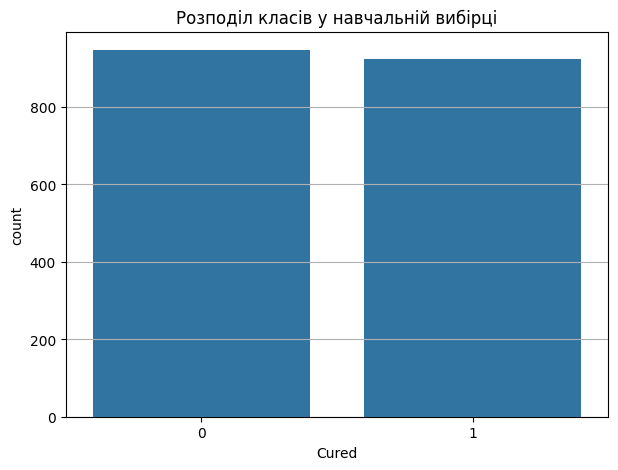

In [23]:
# Підрахунок кількості об'єктів кожного класу
print("Кількість об'єктів у кожному класі:")
print(y_train.value_counts())

plt.figure(figsize=(7, 5))
sns.countplot(x=y_train)

plt.title("Розподіл класів у навчальній вибірці")
plt.xlabel("Cured")
plt.xticks([0, 1], ["0", "1"])
plt.grid(axis="y")
plt.show()

**Висновок:**  
Навчальна вибірка містить 1870 записів: 946 об'єктів належать до класу 0 (не вилікувано), а 924 — до класу 1 (вилікувано). Розподіл становить приблизно 50,6% та 49,4% відповідно. Отже, класи є добре збалансованими, тому суттєвої переваги одного класу над іншим немає. Це позитивно впливає на навчання та оцінювання моделі класифікації.

### 6. Дослідження викидів на навчальних даних

Побудуйте діаграми розмаху для ознак `X_train`. За правилом **1,5 IQR** знайдіть кількість потенційних викидів у кожній ознаці.

На основному етапі **не видаляйте викиди автоматично**. За бажанням пізніше проведіть окремий експеримент із видаленням тільки з навчальної вибірки.

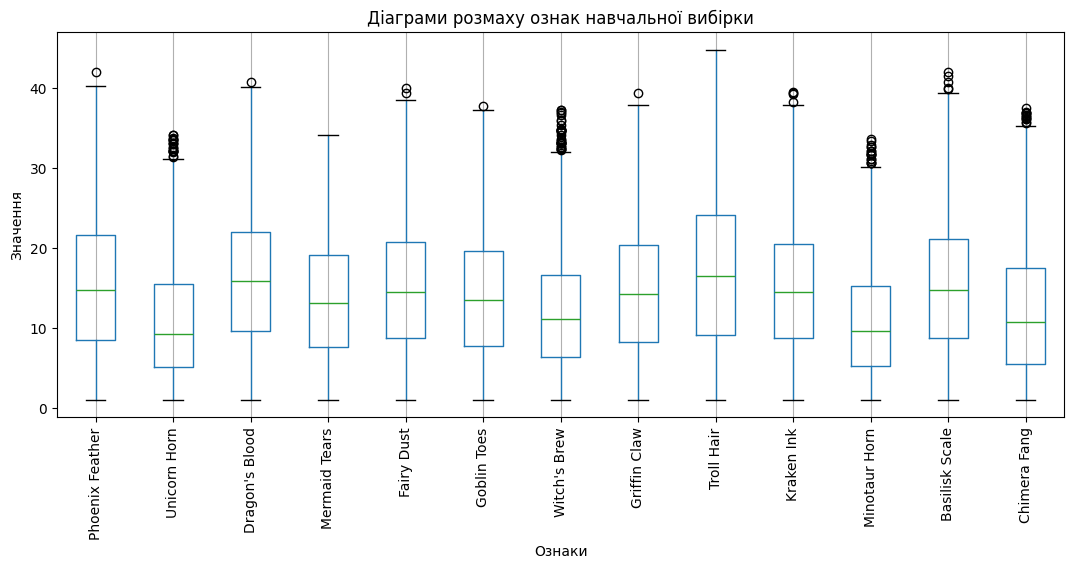

In [24]:
plt.figure(figsize=(13, 5))

X_train.boxplot(rot=90)

plt.title("Діаграми розмаху ознак навчальної вибірки")
plt.xlabel("Ознаки")
plt.ylabel("Значення")
plt.grid(axis="y")
plt.show()

In [26]:
Q1 = X_train.quantile(0.25)
Q3 = X_train.quantile(0.75)

IQR = Q3 - Q1

lower_bound = Q1 - 1.5 * IQR
upper_bound = Q3 + 1.5 * IQR

outliers_count = (
    (X_train < lower_bound) |
    (X_train > upper_bound)
).sum()

outliers_count = outliers_count.sort_values(ascending=False)

display(outliers_count.to_frame(name="Кількість викидів"))

,Кількість викидів
Witch's Brew,33
Unicorn Horn,20
Minotaur Horn,18
Chimera Fang,13
Basilisk Scale,5
Kraken Ink,4
Fairy Dust,2
Phoenix Feather,1
Dragon's Blood,1
Griffin Claw,1


**Висновок про викиди:**  
Найбільшу кількість потенційних викидів виявлено в ознаці Witch's Brew — 33, Unicorn Horn — 20 та Minotaur Horn — 18. В ознаках Mermaid Tears і Troll Hair потенційних викидів не виявлено. Загалом найбільше відхилень спостерігається в перших трьох зазначених ознаках. Автоматично видаляти такі значення не потрібно, оскільки вони можуть бути природними особливостями даних, а не помилками. Тому для подальшого навчання моделі залишаємо всі записи.

### 7. Кореляційний аналіз на навчальній вибірці

1. Побудуйте кореляційну матрицю ознак **за модулем** (`.abs()`).
2. Відобразіть її у вигляді `heatmap` із **замаскованим верхнім трикутником** (`np.triu`).
3. Окремо знайдіть кореляцію ознак із цільовою змінною `Cured` **тільки для навчальної вибірки**.

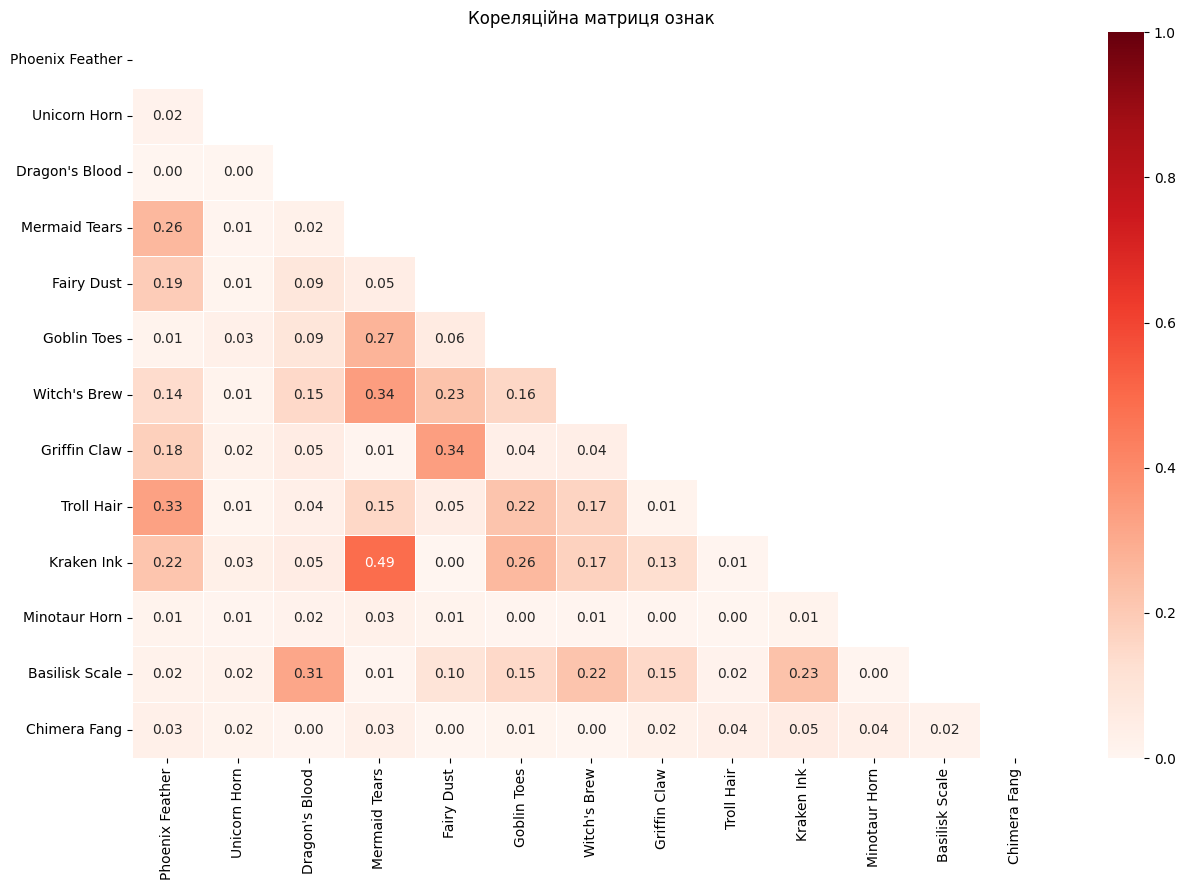

In [30]:
# Обчислення кореляційної матриці
mtx = X_train.corr().abs()

mask = np.triu(np.ones_like(mtx, dtype=bool))

plt.figure(figsize=(13, 9))

sns.heatmap(
    mtx,
    mask=mask,
    annot=True,
    cmap="Reds", vmin=0, vmax=1,
    fmt=".2f",
    linewidths=0.5
)

plt.title("Кореляційна матриця ознак")
plt.tight_layout()
plt.show()

In [32]:
train_corr = pd.concat([X_train, y_train], axis=1).corr()

cured_corr = train_corr["Cured"].drop("Cured")

cured_corr = cured_corr.reindex(
    cured_corr.abs().sort_values(ascending=False).index
)

print("Кореляція ознак із Cured:")
display(cured_corr.to_frame(name="Кореляція"))

Кореляція ознак із Cured:


,Кореляція
Troll Hair,0.488783
Witch's Brew,0.246989
Goblin Toes,0.052573
Chimera Fang,0.047292
Basilisk Scale,-0.042277
Kraken Ink,-0.026598
Minotaur Horn,0.021922
Phoenix Feather,0.020527
Fairy Dust,0.014223
Dragon's Blood,0.010119


**Висновок про кореляції:**  
Найсильніший позитивний зв'язок із цільовою змінною Cured має ознака Troll Hair (0.4888). Також помітний зв'язок спостерігається в Witch's Brew (0.2470). Інші ознаки мають дуже слабку кореляцію з цільовою змінною, оскільки їхні значення близькі до нуля. Отже, найбільший вплив на результат класифікації за лінійним зв'язком можуть мати Troll Hair та Witch's Brew.

### 8. Стандартизація ознак

Скористайтеся `StandardScaler`. Для `X_train` — `fit_transform()`, для `X_test` — тільки `transform()`.

In [34]:
scaler = StandardScaler()

X_train_scaled = scaler.fit_transform(X_train)

X_test_scaled = scaler.transform(X_test)

### 9. Логістична регресія

Навчіть `LogisticRegression` на стандартизованих навчальних даних. Оцініть модель на тестовій вибірці: **Accuracy**, `classification_report`.

In [35]:
model = LogisticRegression(random_state=42)

model.fit(X_train_scaled, y_train)

y_pred = model.predict(X_test_scaled)

accuracy = accuracy_score(y_test, y_pred)

print("Accuracy:", round(accuracy, 4))

print("\nКласифікаційний звіт:")
print(classification_report(y_test, y_pred))

Accuracy: 0.8932

Класифікаційний звіт:
              precision    recall  f1-score   support

           0       0.89      0.90      0.89       231
           1       0.90      0.89      0.89       237

    accuracy                           0.89       468
   macro avg       0.89      0.89      0.89       468
weighted avg       0.89      0.89      0.89       468



### 10. Матриця помилок і приклади прогнозів

Побудуйте `confusion_matrix(y_test, y_pred)` та **теплову карту** (`sns.heatmap` із `annot=True`, `fmt='d'`). Порівняйте справжні й передбачені класи для **10 випадкових** тестових спостережень.

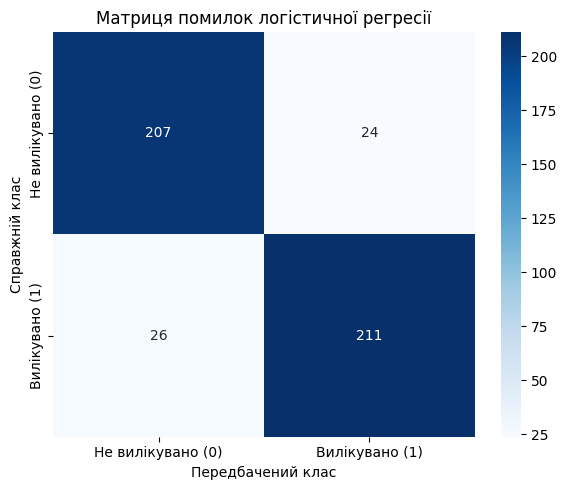

In [37]:
conf = confusion_matrix(y_test, y_pred)

# Побудова теплової карти
plt.figure(figsize=(6, 5))

sns.heatmap(
    conf,
    annot=True,
    fmt="d",
    cmap="Blues",
    xticklabels=["Не вилікувано (0)", "Вилікувано (1)"],
    yticklabels=["Не вилікувано (0)", "Вилікувано (1)"]
)

plt.title("Матриця помилок логістичної регресії")
plt.xlabel("Передбачений клас")
plt.ylabel("Справжній клас")
plt.tight_layout()
plt.show()

In [38]:
predictions = pd.DataFrame({
    "Справжній клас": y_test,
    "Передбачений клас": y_pred
})

display(predictions.sample(10, random_state=42))

,Справжній клас,Передбачений клас
1133,0,1
1018,0,0
1761,1,0
564,1,1
1467,1,1
1927,0,0
408,1,1
2094,1,1
532,0,0
291,1,1


**Висновок щодо якості логістичної регресії:**  
Логістична регресія показала точність Accuracy ≈ 89, що свідчить про достатньо високу якість класифікації. Значення Precision, Recall та F1-score для обох класів становлять приблизно 0,89–0,90, тобто модель досить рівномірно розпізнає обидва класи. За наведеними 10 випадковими прогнозами видно, що більшість результатів визначено правильно, але є два помилкові передбачення. Матриця помилок дозволяє детальніше оцінити типи помилок: хибнопозитивні та хибнонегативні прогнози. Отже, Accuracy недостатньо для повної оцінки моделі, тому важливо також враховувати Precision, Recall та F1-score.

### 11. Підбір гіперпараметрів

Задайте набори параметрів для `LogisticRegression`. Проведіть підбір через **GridSearchCV** та **RandomizedSearchCV** із `cv=3`, `scoring='accuracy'`. Порівняйте найкращі параметри та отриману якість.

*Підказка:* дослідіть параметри `C`, `solver`, `max_iter`. Підбір виконуйте на **навчальній** вибірці.

In [41]:
param_grid = {
    "C": [0.01, 0.1, 1, 10, 100],
    "solver": ["lbfgs", "liblinear"],
    "max_iter": [100, 200, 500]
}

param_dist = {
    "C": [0.001, 0.01, 0.1, 1, 10, 100],
    "solver": ["lbfgs", "liblinear", "newton-cg"],
    "max_iter": [100, 200, 500, 1000]
}

In [42]:
grid_search = GridSearchCV(
    LogisticRegression(random_state=42),
    param_grid,
    cv=3,
    scoring="accuracy",
    n_jobs=-1
)

grid_search.fit(X_train_scaled, y_train)

print("Найкращі параметри GridSearchCV:")
print(grid_search.best_params_)

print("Найкраща Accuracy:")
print(round(grid_search.best_score_, 4))

Найкращі параметри GridSearchCV:
{'C': 10, 'max_iter': 100, 'solver': 'lbfgs'}
Найкраща Accuracy:
0.8674


In [43]:
random_search = RandomizedSearchCV(
    LogisticRegression(random_state=42),
    param_dist,
    n_iter=20,
    cv=3,
    scoring="accuracy",
    random_state=42,
    n_jobs=-1
)

random_search.fit(X_train_scaled, y_train)

print("Найкращі параметри RandomizedSearchCV:")
print(random_search.best_params_)

print("Найкраща Accuracy:")
print(round(random_search.best_score_, 4))

Найкращі параметри RandomizedSearchCV:
{'solver': 'newton-cg', 'max_iter': 100, 'C': 100}
Найкраща Accuracy:
0.8674


In [44]:
if grid_search.best_score_ >= random_search.best_score_:
    best_model = grid_search.best_estimator_
    print("Обрано GridSearchCV")
else:
    best_model = random_search.best_estimator_
    print("Обрано RandomizedSearchCV")

# Прогнозування на тестовій вибірці
y_pred_best = best_model.predict(X_test_scaled)

print("\nAccuracy на тестовій вибірці:",
      round(accuracy_score(y_test, y_pred_best), 4))

print("\nКласифікаційний звіт:")
print(classification_report(y_test, y_pred_best))

Обрано GridSearchCV

Accuracy на тестовій вибірці: 0.8932

Класифікаційний звіт:
              precision    recall  f1-score   support

           0       0.89      0.90      0.89       231
           1       0.90      0.89      0.89       237

    accuracy                           0.89       468
   macro avg       0.89      0.89      0.89       468
weighted avg       0.89      0.89      0.89       468



**Висновок про підбір параметрів:**  
Для підбору гіперпараметрів логістичної регресії було використано GridSearchCV та RandomizedSearchCV. Обидва методи показали однакову найкращу Accuracy — 0.8674. GridSearchCV обрав параметри C=10, solver='lbfgs', max_iter=100, тому для подальшої роботи було використано саме його. Після підбору параметрів Accuracy на тестовій вибірці залишилася 0.8932, тобто порівняно з базовою моделлю покращення не відбулося.

### 12. Порівняння трьох моделей

Побудуйте також **метод опорних векторів (`SVC`)** і **дерево рішень (`DecisionTreeClassifier`)**. Порівняйте ці дві моделі з логістичною регресією за **Accuracy** та **F1-score** на однаковій тестовій вибірці. Оберіть найкращу модель і поясніть вибір.

In [45]:
models = {
    "Logistic Regression": best_model,
    "SVC": SVC(),
    "Decision Tree": DecisionTreeClassifier(random_state=42)
}

results = []

# Навчання та оцінювання моделей
for name, model in models.items():
    model.fit(X_train_scaled, y_train)

    y_pred_model = model.predict(X_test_scaled)

    results.append({
        "Модель": name,
        "Accuracy": accuracy_score(y_test, y_pred_model),
        "F1-score": f1_score(y_test, y_pred_model)
    })


In [46]:
# Таблиця порівняння
results_df = pd.DataFrame(results)

results_df = results_df.sort_values(
    by="F1-score",
    ascending=False
)

display(results_df.round(4))

,Модель,Accuracy,F1-score
1,SVC,0.9594,0.9600
0,Logistic Regression,0.8932,0.8941
2,Decision Tree,0.8654,0.8657


In [47]:
# Визначення найкращої моделі за F1-score
best_result = results_df.iloc[0]

print("Найкраща модель:", best_result["Модель"])
print("Accuracy:", round(best_result["Accuracy"], 4))
print("F1-score:", round(best_result["F1-score"], 4))

Найкраща модель: SVC
Accuracy: 0.9594
F1-score: 0.96


### 13. Висновки до лабораторної роботи

**1. Які особливості даних виявлено під час первинного аналізу?**

Набір даних містить 2338 записів, 13 числових ознак та цільову змінну Cured, яка має два класи: 0 і 1. Отже, задача належить до бінарної класифікації.

**2. Що показали дослідження викидів і кореляцій на навчальній вибірці?**

Під час аналізу було виявлено викиди в декількох ознаках, найбільше — у Witch's Brew (33) та Unicorn Horn (20). Водночас автоматично видаляти їх не потрібно, оскільки вони можуть бути важливими спостереженнями. Кореляційний аналіз показав, що найбільший зв'язок із цільовою змінною має Troll Hair (0.4888), а також Witch's Brew (0.2470). Інші ознаки мають слабкий зв'язок із результатом.

**3. Якої якості досягла базова логістична регресія?**

Базова модель логістичної регресії показала Accuracy 0.8932 та F1-score 0.8941. Показники precision, recall і F1-score для обох класів становлять приблизно 0.89–0.90, що свідчить про достатньо хорошу та збалансовану якість класифікації.

**4. Чи покращив підбір гіперпараметрів метрики моделі?**

Підбір параметрів за допомогою GridSearchCV та RandomizedSearchCV не покращив якість моделі на тестовій вибірці. Обидва методи отримали однакову найкращу Accuracy під час крос-валідації — 0.8674, а після підбору параметрів тестова Accuracy залишилася 0.8932.

**5. Яка з трьох моделей виявилася найкращою? Обґрунтуйте.**

Найкращою моделлю виявилася SVC, яка показала Accuracy 0.9594 та F1-score 0.9600. Вона перевершила логістичну регресію та дерево рішень за обома показниками. Це свідчить про те, що SVC найкраще впоралася із завданням класифікації на цьому наборі даних.

**Загальний висновок:**

Під час лабораторної роботи було виконано аналіз даних, досліджено викиди та кореляції, побудовано й оцінено модель логістичної регресії, а також проведено підбір її гіперпараметрів. Порівняння трьох алгоритмів показало, що найкращий результат забезпечила модель SVC з Accuracy 95.94% та F1-score 96%. Отже, для дослідженого набору даних SVC виявилася найефективнішим алгоритмом класифікації.